In [1]:
# Locate the repository after moving notebooks into notebook/.
from pathlib import Path
import os
import sys

REPO_ROOT = next((path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                  if (path / "main.py").is_file() and (path / "dataset").is_dir()), None)
if REPO_ROOT is None:
    raise FileNotFoundError("Start Jupyter from the repository or a directory inside it.")
os.chdir(REPO_ROOT)
for path in (REPO_ROOT, REPO_ROOT / "clean_dataset"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))
(REPO_ROOT / "result/comparisons").mkdir(parents=True, exist_ok=True)


## MRI model comparison: 3D CNN versus ViT
Compare saved 3D CNN and ViT experiments using every available numeric fold, excluding average rows. The default is LGG. The table and plots report training/validation C-index and loss, with mean ± fold standard deviation; a separate plot shows validation C-index by fold. Images are exported as PNG/PDF and the metrics as CSV. Losses, preprocessing, patient splits, and checkpoint selection may differ across saved runs, so these are descriptive comparisons, not proof of an architecture-only advantage. The section is self-contained and does not require prediction CSVs or raw MRI files.

**Average C-index** = (mean training C-index + mean validation C-index) / 2 for each model. This descriptive average is not a held-out performance metric. There is no average row across models.

Model,Cohort,Folds,Loss function,Training C-index,Validation C-index,Training loss,Validation loss,Average C-index
3D CNN,GBM,4,NLLSurvLoss,0.505 ± 0.010,0.522 ± 0.073,1.476 ± 0.025,1.490 ± 0.111,0.514
ViT,GBM,4,NLLSurvLoss,0.783 ± 0.030,0.518 ± 0.044,1.044 ± 0.012,1.664 ± 0.153,0.650


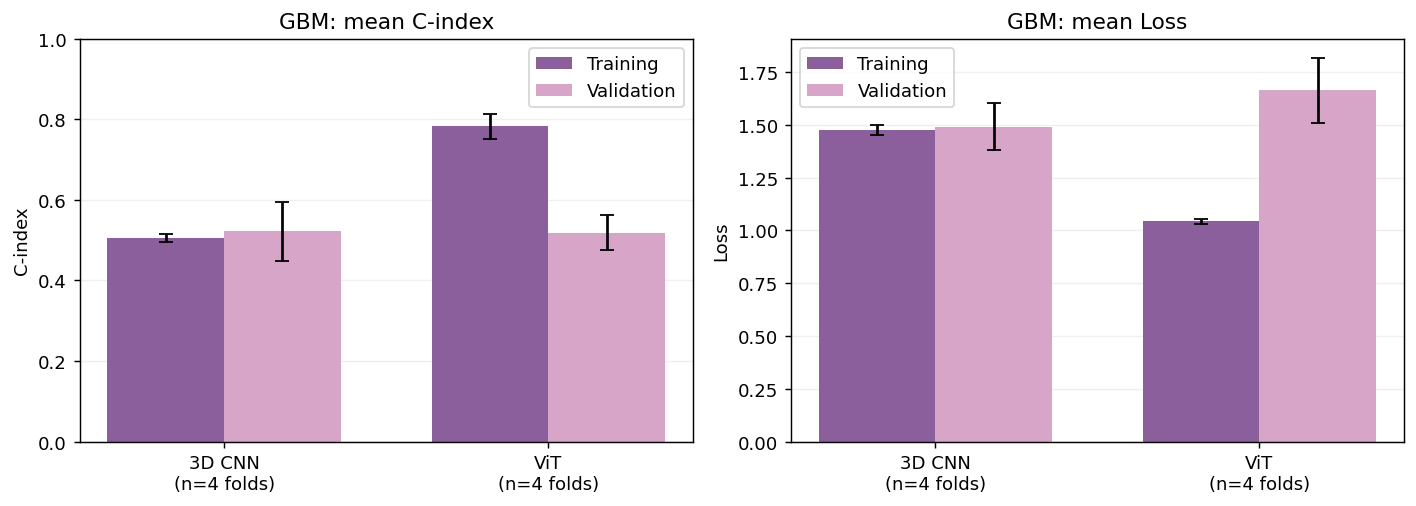

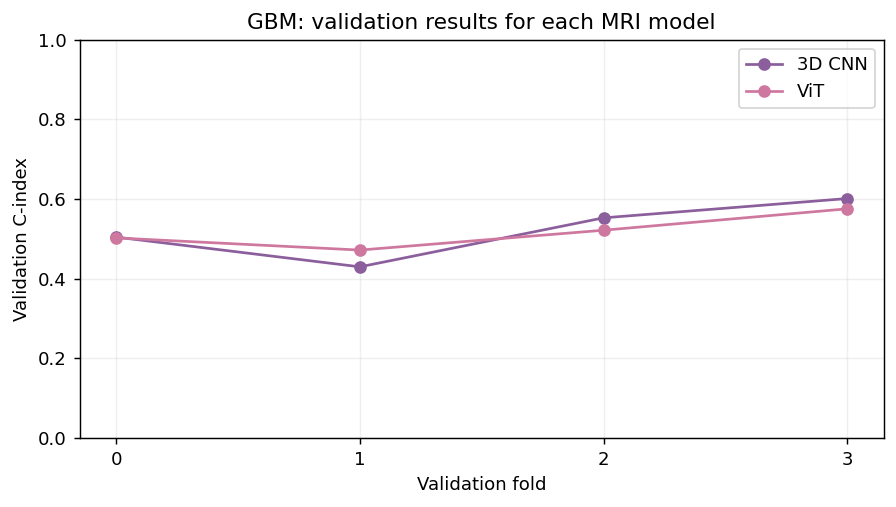

Saved figures and comparison CSVs to: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/comparisons/mri_visualization
Error bars show fold standard deviation. Loss magnitudes require matching objectives and bins.
Matching fold numbers do not prove identical patient splits. Compare saved experiments accordingly.


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

MRI_COMPARISON_COHORT = "gbm"  # Change to "gbm" when both model results are available.
MRI_RESULT_ROOT = next(p / "result" for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                       if (p / "main.py").is_file() and (p / "result").is_dir())
MRI_COMPARISON_PATHS = {
    "3D CNN": MRI_RESULT_ROOT / "3dcnn" / MRI_COMPARISON_COHORT / "summary.csv",
    "ViT": MRI_RESULT_ROOT / "ViT" / MRI_COMPARISON_COHORT / "summary.csv",
}
MRI_COMPARISON_DIR = MRI_RESULT_ROOT / "comparisons/mri_visualization"
MRI_COMPARISON_DIR.mkdir(parents=True, exist_ok=True)
MRI_METRICS = {
    "train_cindex": "Training C-index", "final_val_cindex": "Validation C-index",
    "train_loss": "Training loss", "final_val_loss": "Validation loss",
}
mri_model_folds, mri_comparison_rows = {}, []
for name, summary_path in MRI_COMPARISON_PATHS.items():
    if not summary_path.exists():
        print(f"{name}: no saved summary at {summary_path}")
        continue
    frame = pd.read_csv(summary_path)
    fold_number = pd.to_numeric(frame["fold"], errors="coerce")
    frame = frame.loc[fold_number.notna() & (fold_number >= 0)
                      & (fold_number % 1 == 0)].copy()
    frame["fold"] = pd.to_numeric(frame["fold"]).astype(int)
    if frame.empty:
        print(f"{name}: no numeric fold rows available.")
        continue
    if frame["fold"].duplicated().any():
        raise ValueError(f"Duplicate fold rows in {summary_path}")
    row = {"Model": name, "Cohort": MRI_COMPARISON_COHORT.upper(), "Folds": len(frame)}
    for metric, label in MRI_METRICS.items():
        frame[metric] = pd.to_numeric(frame[metric], errors="coerce").replace([np.inf, -np.inf], np.nan)
        row[f"{metric}_mean"] = frame[metric].mean()
        row[f"{metric}_std"] = frame[metric].std()
        row[f"{metric}_valid_folds"] = frame[metric].count()
    row["C-index gap"] = (frame["train_cindex"] - frame["final_val_cindex"]).mean()
    row["Loss function"] = ", ".join(frame["loss_func"].dropna().astype(str).unique()) if "loss_func" in frame else "Unknown (not recorded)"
    row["Summary"] = str(summary_path)
    mri_comparison_rows.append(row)
    mri_model_folds[name] = frame.sort_values("fold")

mri_model_comparison = pd.DataFrame(mri_comparison_rows)
if mri_model_comparison.empty:
    print("No saved MRI model results found. Train the models first.")
else:
    mri_model_comparison["Average C-index"] = (mri_model_comparison["train_cindex_mean"] + mri_model_comparison["final_val_cindex_mean"]) / 2
    mri_comparison_table = mri_model_comparison[["Model", "Cohort", "Folds", "Loss function"]].copy()
    for metric, label in MRI_METRICS.items():
        mri_comparison_table[label] = [
            "Unavailable" if pd.isna(mean) else f"{mean:.3f}" if pd.isna(std)
            else f"{mean:.3f} ± {std:.3f}"
            for mean, std in zip(mri_model_comparison[f"{metric}_mean"], mri_model_comparison[f"{metric}_std"])
        ]
    mri_comparison_table["Average C-index"] = mri_model_comparison["Average C-index"].round(3)
    display(mri_comparison_table)
    prefix = f"{MRI_COMPARISON_COHORT}_3dcnn_vs_vit"
    mri_model_comparison.to_csv(MRI_COMPARISON_DIR / f"{prefix}_mean_results.csv", index=False)
    mri_comparison_table.to_csv(MRI_COMPARISON_DIR / f"{prefix}_comparison_table.csv", index=False)
    pd.concat([frame.assign(Model=name) for name, frame in mri_model_folds.items()],
              ignore_index=True).to_csv(MRI_COMPARISON_DIR / f"{prefix}_fold_results.csv", index=False)

    def save_mri_comparison(fig, suffix):
        fig.tight_layout()
        for extension in ("png", "pdf"):
            fig.savefig(MRI_COMPARISON_DIR / f"{prefix}_{suffix}.{extension}", dpi=300, bbox_inches="tight")
        plt.show()
        plt.close(fig)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    positions = np.arange(len(mri_model_comparison))
    labels = [f"{row['Model']}\n(n={row['Folds']} folds)" for _, row in mri_model_comparison.iterrows()]
    for ax, train, val, ylabel in [
        (axes[0], "train_cindex", "final_val_cindex", "C-index"),
        (axes[1], "train_loss", "final_val_loss", "Loss"),
    ]:
        for offset, metric, label, color in [
            (-0.18, train, "Training", "#8B5E9C"),
            (0.18, val, "Validation", "#D6A5C8"),
        ]:
            means = mri_model_comparison[f"{metric}_mean"]
            errors = mri_model_comparison[f"{metric}_std"].fillna(0)
            ax.bar(positions + offset, means, width=0.36, yerr=errors,
                   capsize=4, label=label, color=color)
        ax.set(xticks=positions, xticklabels=labels, ylabel=ylabel,
               title=f"{MRI_COMPARISON_COHORT.upper()}: mean {ylabel}")
        ax.grid(axis="y", alpha=0.2)
        ax.set_axisbelow(True)
        ax.legend()
    axes[0].set_ylim(0, 1)
    save_mri_comparison(fig, "training_validation")

    fig, ax = plt.subplots(figsize=(7, 4))
    for (name, frame), color in zip(mri_model_folds.items(), ["#8B5E9C", "#CF789F"]):
        ax.plot(frame["fold"], frame["final_val_cindex"], marker="o", label=name, color=color)
    fold_ids = sorted({int(fold) for frame in mri_model_folds.values() for fold in frame["fold"]})
    ax.set(xticks=fold_ids, xlabel="Validation fold", ylabel="Validation C-index", ylim=(0, 1),
           title=f"{MRI_COMPARISON_COHORT.upper()}: validation results for each MRI model")
    ax.grid(alpha=0.2)
    ax.legend()
    save_mri_comparison(fig, "validation_folds")
    print("Saved figures and comparison CSVs to:", MRI_COMPARISON_DIR)
    print("Error bars show fold standard deviation. Loss magnitudes require matching objectives and bins.")
    print("Matching fold numbers do not prove identical patient splits. Compare saved experiments accordingly.")



# ViTMRI prediction comparison

Select one prediction CSV below. Predictions are survival classes, not tumor segmentation.

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "result").is_dir():
    ROOT = ROOT.parent
PREDICTION_PATH = ROOT / "result/split_ViT_lgg_2_predictions.csv"
results = pd.read_csv(PREDICTION_PATH)
OUTPUT_DIR = ROOT / "result/comparisons/mri_visualization"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_PREFIX = PREDICTION_PATH.stem.replace("_predictions", "")

def save_plot(filename):
    path = OUTPUT_DIR / filename
    plt.gcf().savefig(path, dpi=300, bbox_inches="tight", facecolor="white")
    print("Saved:", path)
print(f"{len(results)} sample predictions; {results['case_id'].nunique()} patients")
print(f"Sample accuracy: {(results['label'] == results['prediction']).mean():.1%}")
display(results.head())


64 sample predictions; 16 patients
Sample accuracy: 25.0%


,case_id,label,prediction,correct,event_time,censorship,risk,inference_time_seconds,prob_class_0,prob_class_1,...,event_bin_observed,survival_tail_probability,hazard_0,survival_0,hazard_1,survival_1,hazard_2,survival_2,hazard_3,survival_3
0,TCGA-CS-5393,2,3,False,40.733334,1.0,-3.623236,0.0039,0.007549,0.023595,...,False,0.744801,0.007549,0.992451,0.023775,0.968856,0.053391,0.917128,0.187898,0.744801
1,TCGA-CS-5393,2,3,False,40.733334,1.0,-3.471608,0.0039,0.015196,0.030228,...,False,0.661769,0.015196,0.984804,0.030695,0.954576,0.088120,0.870459,0.239746,0.661769
2,TCGA-CS-5393,2,3,False,40.733334,1.0,-3.532216,0.0039,0.017296,0.031630,...,False,0.711957,0.017296,0.982704,0.032186,0.951074,0.067915,0.886482,0.196874,0.711957
3,TCGA-CS-5393,2,3,False,40.733334,1.0,-3.595270,0.0039,0.007192,0.025664,...,False,0.719326,0.007192,0.992808,0.025850,0.967144,0.052889,0.915992,0.214703,0.719326
4,TCGA-CS-6188,2,3,False,27.133333,0.0,-3.518180,0.0039,0.017837,0.042918,...,True,0.696336,0.017837,0.982163,0.043697,0.939246,0.041320,0.900436,0.226668,0.696336


In [4]:
# Average probabilities across samples belonging to the same patient.
prob_cols = [f"prob_class_{i}" for i in range(4)]
if (results.groupby("case_id")["label"].nunique() > 1).any():
    raise ValueError("A patient has inconsistent reference labels.")
patients = results.groupby("case_id")[prob_cols].mean()
patients["label"] = results.groupby("case_id")["label"].first().astype(int)
patients["prediction"] = patients[prob_cols].to_numpy().argmax(axis=1)
patients["correct"] = patients["label"] == patients["prediction"]
print(f"Patient accuracy (averaged probabilities): {patients['correct'].mean():.1%}")
display(patients[["label", "prediction", "correct"]])


Patient accuracy (averaged probabilities): 25.0%


,label,prediction,correct
case_id,,,
TCGA-CS-5393,2,3,False
TCGA-CS-6188,2,3,False
TCGA-CS-6669,3,3,True
TCGA-DU-5872,1,3,False
TCGA-DU-7008,3,3,True
TCGA-DU-7018,2,3,False
TCGA-DU-7299,3,3,True
TCGA-DU-7304,1,3,False
TCGA-DU-8164,1,3,False


Saved: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/comparisons/mri_visualization/split_ViT_lgg_2_class_comparison.png


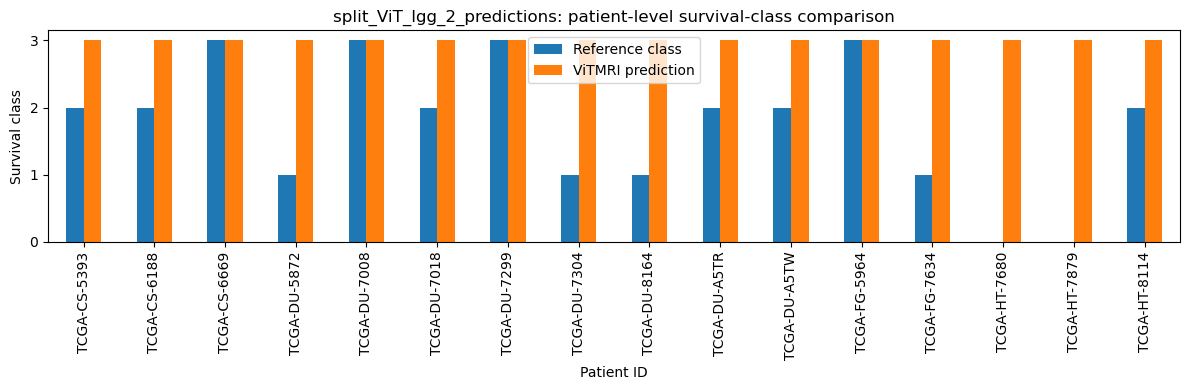

In [5]:
# Compare reference and predicted survival classes for every patient.
patients[["label", "prediction"]].rename(
    columns={"label": "Reference class", "prediction": "ViTMRI prediction"}
).plot.bar(figsize=(12, 4), rot=90)
plt.title(f"{PREDICTION_PATH.stem}: patient-level survival-class comparison")
plt.xlabel("Patient ID")
plt.ylabel("Survival class")
plt.yticks(range(4))
plt.tight_layout()
save_plot(f"{PLOT_PREFIX}_class_comparison.png")
plt.show()


Saved: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/comparisons/mri_visualization/split_ViT_lgg_2_predictions_confusion_matrix.png


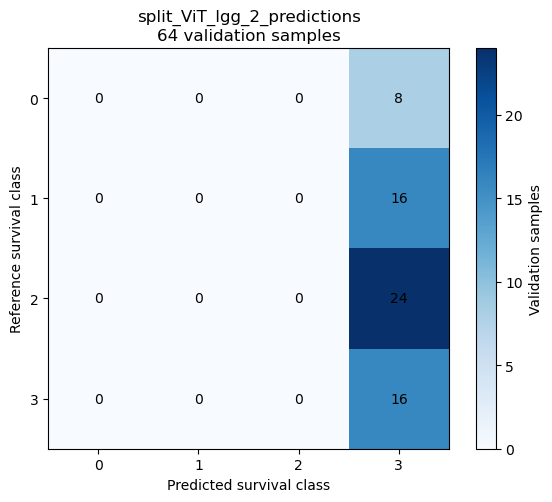

Included all 64 validation samples from this fold.


In [6]:
# Show all validation samples from the single fold selected by PREDICTION_PATH.
validation = pd.read_csv(PREDICTION_PATH)
confusion = pd.crosstab(validation["label"], validation["prediction"]).reindex(
    index=range(4), columns=range(4), fill_value=0
).to_numpy()
assert confusion.sum() == len(validation), "Unexpected class labels in the CSV."

fig, ax = plt.subplots(figsize=(6, 5))
heat = ax.imshow(confusion, cmap="Blues")
for row in range(4):
    for column in range(4):
        ax.text(column, row, confusion[row, column], ha="center", va="center")
ax.set(xticks=range(4), yticks=range(4), xlabel="Predicted survival class",
       ylabel="Reference survival class",
       title=f"{PREDICTION_PATH.stem}\n{len(validation)} validation samples")
fig.colorbar(heat, ax=ax, label="Validation samples")
fig.tight_layout()
save_plot(f"{PREDICTION_PATH.stem}_confusion_matrix.png")
plt.show()
print(f"Included all {len(validation)} validation samples from this fold.")


Saved: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/comparisons/mri_visualization/split_ViT_lgg_2_TCGA-CS-5393_probabilities.png


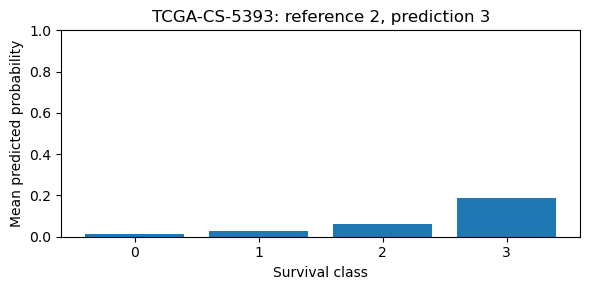

In [7]:
# Choose a patient to inspect the averaged class probabilities.
PATIENT_ID = patients.index[0]  # Replace with another ID from the table above.
patient = patients.loc[PATIENT_ID]
plt.figure(figsize=(6, 3))
plt.bar(range(4), patient[prob_cols].astype(float))
plt.xticks(range(4))
plt.ylim(0, 1)
plt.xlabel("Survival class")
plt.ylabel("Mean predicted probability")
plt.title(f"{PATIENT_ID}: reference {int(patient['label'])}, prediction {int(patient['prediction'])}")
plt.tight_layout()
save_plot(f"{PLOT_PREFIX}_{PATIENT_ID}_probabilities.png")
plt.show()


## Training and validation results — GBM
Final metrics and epoch histories are read from `result/ViT/gbm/`.
Training now saves histories in this dataset-specific folder. Rerun `script/mri.sh` to generate missing histories; older shared histories are not used because they do not match the GBM summary. Validation is recorded only after training.


Training/validation summary: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/ViT/lgg/summary.csv


,fold,train_loss,final_val_loss,train_cindex,final_val_cindex
0,0,0.523421,1.120929,0.809856,0.539062
1,1,0.648790,1.130249,0.552885,0.597426
2,2,0.526682,0.796284,0.808824,0.597222
3,3,0.620351,0.597120,0.788609,0.450658


Saved: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/comparisons/mri_visualization/ViT_lgg_training_validation.png


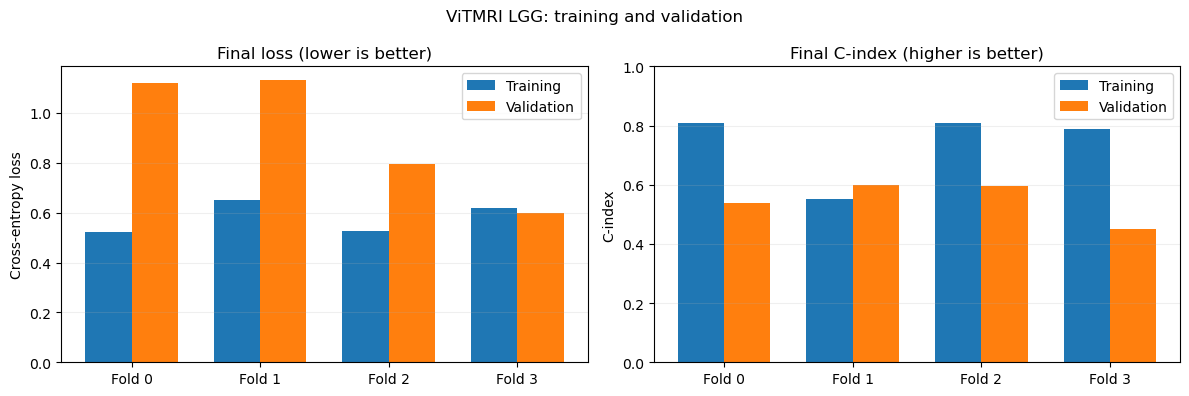

Mean training C-index: 0.740
Mean validation C-index: 0.546
Mean training loss: 0.580
Mean validation loss: 0.911


In [8]:
COHORT = PREDICTION_PATH.stem.rsplit("_", 2)[0].replace("split_ViT_", "").removesuffix(".csv")
SUMMARY_PATH = ROOT / "result/ViT" / COHORT / "summary.csv"
summary = pd.read_csv(SUMMARY_PATH)
print("Training/validation summary:", SUMMARY_PATH)
folds = summary[summary["fold"].astype(str) != "average"].copy()
folds["fold"] = folds["fold"].astype(int)
folds = folds.sort_values("fold")
display(folds[["fold", "train_loss", "final_val_loss", "train_cindex", "final_val_cindex"]])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(len(folds))
for ax, train_col, val_col, title in [
    (axes[0], "train_loss", "final_val_loss", "Final loss (lower is better)"),
    (axes[1], "train_cindex", "final_val_cindex", "Final C-index (higher is better)"),
]:
    ax.bar(x - 0.18, folds[train_col], width=0.36, label="Training")
    ax.bar(x + 0.18, folds[val_col], width=0.36, label="Validation")
    ax.set_xticks(x, [f"Fold {fold}" for fold in folds["fold"]])
    ax.set_title(title)
    ax.legend()
    ax.grid(axis="y", alpha=0.2)
axes[0].set_ylabel("Cross-entropy loss")
axes[1].set_ylabel("C-index")
axes[1].set_ylim(0, 1)
fig.suptitle(f"ViTMRI {SUMMARY_PATH.parent.name.upper()}: training and validation")
fig.tight_layout()
save_plot(f"ViT_{SUMMARY_PATH.parent.name}_training_validation.png")
plt.show()

print(f"Mean training C-index: {folds['train_cindex'].mean():.3f}")
print(f"Mean validation C-index: {folds['final_val_cindex'].mean():.3f}")

print(f"Mean training loss: {folds['train_loss'].mean():.3f}")
print(f"Mean validation loss: {folds['final_val_loss'].mean():.3f}")



Saved: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/comparisons/mri_visualization/ViT_lgg_epoch_curves.png


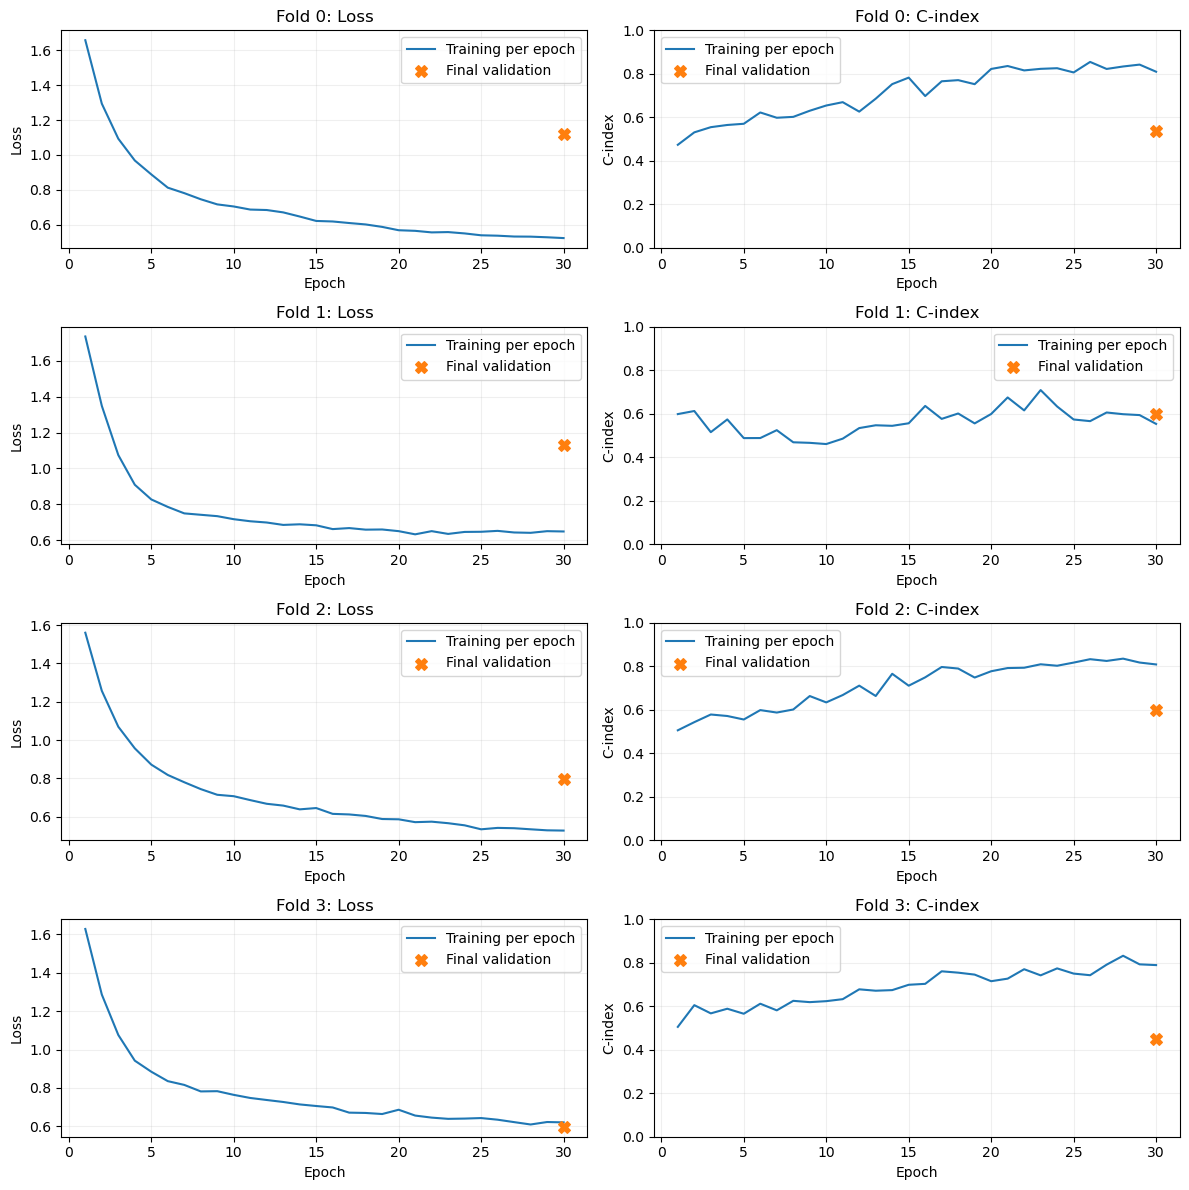

In [9]:
# Plot epoch training curves and the final validation point for each fold.
histories = {}
for _, row in folds.iterrows():
    fold = int(row["fold"])
    path = SUMMARY_PATH.parent / f"training_history_fold_{fold}.csv"
    if not path.exists():
        print(f"Fold {fold}: no saved MRI history at {path}. Rerun script/mri.sh to generate it.")
        continue
    history = pd.read_csv(path)
    if history.empty or not {"train_loss", "train_cindex"}.issubset(history.columns):
        print(f"Skipping fold {fold}: missing training metrics.")
        continue
    if not np.allclose(history.iloc[-1][["train_loss", "train_cindex"]].to_numpy(dtype=float),
                       [row["train_loss"], row["train_cindex"]], rtol=1e-4, atol=1e-6):
        print(f"Skipping fold {fold}: history does not match the MRI summary.")
        continue
    histories[fold] = history

if histories:
    fig, axes = plt.subplots(len(histories), 2, figsize=(12, 3 * len(histories)), squeeze=False)
    for index, (fold, history) in enumerate(histories.items()):
        row = folds.set_index("fold").loc[fold]
        epochs = np.arange(1, len(history) + 1)
        for ax, train_col, val_col, ylabel in [
            (axes[index, 0], "train_loss", "final_val_loss", "Loss"),
            (axes[index, 1], "train_cindex", "final_val_cindex", "C-index"),
        ]:
            ax.plot(epochs, history[train_col], label="Training per epoch")
            ax.scatter(epochs[-1], row[val_col], color="tab:orange", marker="X", s=70,
                       label="Final validation", zorder=3)
            ax.set(title=f"Fold {fold}: {ylabel}", xlabel="Epoch", ylabel=ylabel)
            ax.grid(alpha=0.2)
            ax.legend()
        axes[index, 1].set_ylim(0, 1)
    fig.tight_layout()
    save_plot(f"ViT_{SUMMARY_PATH.parent.name}_epoch_curves.png")
    plt.show()
else:
    print("No matching MRI epoch histories; use the final fold comparison above.")


## Preview MRI training and validation splits
The preview reads `--n_folds` from `script/mri.sh`. Each validation fold contains approximately 1 / n_folds of the patients. All scans from a patient stay together. This preview is independent of older prediction CSVs; set `FOLD` to inspect a specific split.


Loaded 102 and 408 patients with MRI metadata.
Loaded 522 patients with clinical labels.
Loaded 83 patients with MRI and clinical labels.
MRI dataset: 83 patients, 408 images
Preview: fold 0 of 4
            Patients  Images
Training          62     248
Validation        21      84


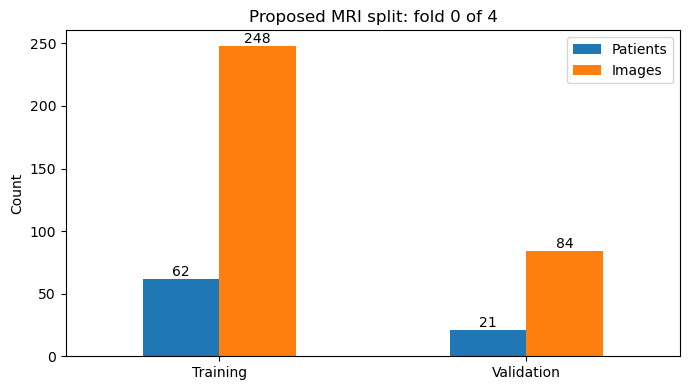

In [10]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

root = Path.cwd().resolve()
if not (root / "dataset").is_dir():
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from dataset.SurvivalMRIDataset import SurvivalMRIDataset

import re
fold_setting = re.search(r"--n_folds\s+(\d+)", (root / "script/mri.sh").read_text())
N_FOLDS = int(fold_setting.group(1)) if fold_setting else 5
FOLD = 0
if not 0 <= FOLD < N_FOLDS:
    raise ValueError("FOLD must be between 0 and N_FOLDS - 1.")
mri = SurvivalMRIDataset(
    label_file=root / "dataset_csv/metadata/clinical_gbm.csv",
    mri_file_name=root / "dataset_csv/mri_data/gbm_mri_metadata.csv",
    mri_dir="/media/licongcong/Data 1/TCGA-GBM/MRI-images",
    seed=42, label_col="CDE_survival_time", n_bins=4, n_classes=4,
    crop_size=(224, 224, 224),
)
validation_patients = mri.metadata.iloc[FOLD::N_FOLDS]["patient_id"]
is_validation = mri.metadata["patient_id"].isin(validation_patients)
preview_splits = {}
for name, patient_rows in [("Training", mri.metadata[~is_validation]),
                           ("Validation", mri.metadata[is_validation])]:
    preview_splits[name] = patient_rows.merge(mri.mri_data, on="patient_id", how="inner")
assert set(preview_splits["Training"].patient_id).isdisjoint(preview_splits["Validation"].patient_id)
counts = pd.DataFrame({
    name: {"Patients": frame.patient_id.nunique(), "Images": len(frame)}
    for name, frame in preview_splits.items()
}).T
print(f"Preview: fold {FOLD} of {N_FOLDS}")
print(counts.to_string())
export_dir = root / "result/comparisons/mri_visualization"
export_dir.mkdir(parents=True, exist_ok=True)
ax = counts.plot.bar(figsize=(7, 4), rot=0, color=["tab:blue", "tab:orange"])
for container in ax.containers:
    ax.bar_label(container)
ax.set(title=f"Proposed MRI split: fold {FOLD} of {N_FOLDS}", ylabel="Count")
plt.tight_layout()
plt.savefig(export_dir / f"gbm_{N_FOLDS}fold_{FOLD}_split_counts.png", dpi=300)
plt.show()


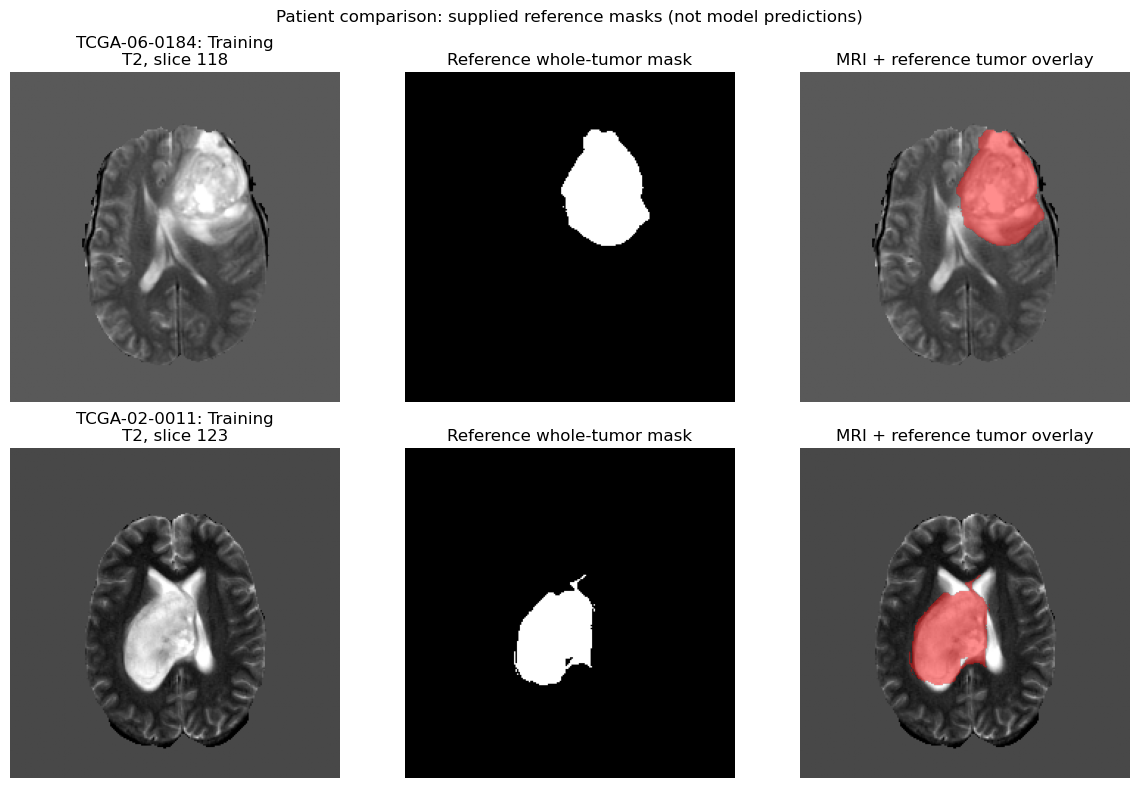

,Patient,Split,Survival time (clinical units),Censorship (1=censored),Reference mask
0,TCGA-06-0184,Training,40.933333,1.0,TCGA-06-0184_2003.07.13_GlistrBoost_ManuallyCo...
1,TCGA-02-0011,Training,21.000000,0.0,TCGA-02-0011_1998.02.01_GlistrBoost_ManuallyCo...


Saved: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/comparisons/mri_visualization/gbm_fold_0_two_patient_reference_comparison.png
Reference masks prefer manually corrected GlistrBoost annotations; all positive labels are shown as whole tumor.


In [11]:
# Compare two patients with their supplied reference tumor masks.
import nibabel as nib
from nibabel.processing import resample_from_to
from matplotlib.colors import ListedColormap
from IPython.display import display

PATIENT_IDS = ["TCGA-06-0184", "TCGA-02-0011"]
SEQUENCE = "t2"
fig, axes = plt.subplots(len(PATIENT_IDS), 3, figsize=(12, 8))
clinical_rows = []
for row, patient_id in enumerate(PATIENT_IDS):
    matches = [(name, frame[frame["patient_id"] == patient_id])
               for name, frame in preview_splits.items() if (frame["patient_id"] == patient_id).any()]
    if not matches:
        raise ValueError(f"Patient is not in the eligible dataset: {patient_id}")
    split_name, patient_scans = matches[0]
    paths = [Path(path) for path in patient_scans["image_path"]]
    paths = sorted(path for path in paths if path.name.lower().endswith(f"_{SEQUENCE}.nii.gz"))
    if not paths:
        raise FileNotFoundError(f"No {SEQUENCE} scan for {patient_id}")
    image_path = paths[0]
    # Match the reference mask to exactly the same patient and scan date.
    prefix = image_path.name.split(f"_{SEQUENCE}.")[0]
    masks = [path for path in image_path.parent.glob(prefix + "_*.nii*")
             if any(marker in path.name.lower() for marker in ("glistrboost", "glisterboots"))]
    if not masks:
        raise FileNotFoundError(f"No reference tumor mask for {image_path.name}")
    mask_path = sorted(masks, key=lambda path: ("manuallycorrected" not in path.name.lower(), path.name))[0]
    image = nib.as_closest_canonical(nib.load(str(image_path)))
    mask = nib.as_closest_canonical(nib.load(str(mask_path)))
    if mask.shape != image.shape or not np.allclose(mask.affine, image.affine):
        mask = resample_from_to(mask, (image.shape, image.affine), order=0)
    tumor_mask = np.rint(mask.get_fdata()).astype(np.int16).transpose(2, 1, 0)
    if mri.crop_size is not None:
        tumor_mask = mri.crop_mri_volume(tumor_mask, mri.crop_size)
    volume = mri.load_mri_series(str(image_path))[0].numpy()
    # Use the same slice for the scan, reference mask, and overlay.
    tumor_counts = (tumor_mask > 0).sum(axis=(1, 2))
    index = int(tumor_counts.argmax()) if tumor_counts.any() else volume.shape[0] // 2
    image_slice, mask_slice = volume[index], tumor_mask[index]
    foreground = image_slice[image_slice != 0]
    limits = np.percentile(foreground, [1, 99]) if foreground.size else (0, 1)
    axes[row, 0].imshow(image_slice, cmap="gray", origin="lower", vmin=limits[0], vmax=limits[1])
    axes[row, 0].set_title(f"{patient_id}: {split_name}\n{SEQUENCE.upper()}, slice {index}")
    axes[row, 1].imshow(mask_slice > 0, cmap="gray", origin="lower", vmin=0, vmax=1)
    axes[row, 1].set_title("Reference whole-tumor mask")
    axes[row, 2].imshow(image_slice, cmap="gray", origin="lower", vmin=limits[0], vmax=limits[1])
    axes[row, 2].imshow(np.ma.masked_where(mask_slice == 0, mask_slice > 0),
                        cmap=ListedColormap(["red"]), alpha=0.45, origin="lower")
    axes[row, 2].set_title("MRI + reference tumor overlay")
    for ax in axes[row]:
        ax.axis("off")
    clinical = patient_scans.iloc[0]
    clinical_rows.append({"Patient": patient_id, "Split": split_name,
                          "Survival time (clinical units)": clinical[mri.label_col],
                          "Censorship (1=censored)": clinical["censorship"],
                          "Reference mask": mask_path.name})
fig.suptitle("Patient comparison: supplied reference masks (not model predictions)")
fig.tight_layout()
output_path = export_dir / f"gbm_fold_{FOLD}_two_patient_reference_comparison.png"
fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()
display(pd.DataFrame(clinical_rows))
print("Saved:", output_path)
print("Reference masks prefer manually corrected GlistrBoost annotations; all positive labels are shown as whole tumor.")
